# 외국인 자영업자 대상 금융상품(사업자대출·환전/송금) 기획을 위한 공공데이터 분석

**목적** — 한국 거주를 희망하지만 외국인이라는 이유로 금융 접근이 어려운 외국인 자영업자를 위한
대출·환전 상품을 기획하기 위해, 공개된 국가 통계로 **(1) 시장 규모와 성장성, (2) 타겟 세분화,
(3) 지역 거점, (4) 환전·송금 수요, (5) 잠재 시장규모**를 정량화한다.

| 코드 | 출처 | 자료 | 기준시점 |
|---|---|---|---|
| A | 국가데이터처·법무부 「이민자체류실태및고용조사」 보도자료(2023·2024·2025) | 종사상지위·산업·체류자격별 취업자, 소득, 송금, 경제적 어려움 | 각 연도 5월 |
| B | 법무부 「출입국·외국인정책 통계월보」 체류외국인 원본통계표 | 국적×체류자격별 체류외국인 | 2020~2025 12월, 2026.9 |
| C | 법무부 「지역별 외국인(등록+거소) 현황」 | 시군구×체류자격, 시군구×국적 | 2026.9 |
| D | 국세청 「외국인 소득세 신고현황」(e-나라지표 2849) | 외국인 종합소득세 신고 인원·세액 | 2009~2024 |
| E | 한국은행 ECOS 731Y004 | 월평균 원/달러, 원/위안 | 2016.1~2026.10 |
| F | World Bank WDI | 한국발 개인송금 지급액, 송금 상대국 환율 | ~2025 |

원자료 URL·수집일은 `data/SOURCES.md` 참조. 이 노트북은 `data/raw/`의 로컬 파일만 읽으므로 오프라인으로 재실행 가능하다.

In [1]:
import os, sys, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")  # joblib 코어 탐지 경고 방지
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.colors import ListedColormap, BoundaryNorm, TwoSlopeNorm, LinearSegmentedColormap
import statsmodels.api as sm
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

from src import load as L

FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
PROC = ROOT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

### 차트 스타일 (공통)
일관된 팔레트: 범주형 8색은 고정 순서로만 사용, 크기(magnitude)는 단일 파랑 계열, 증감(±)은 파랑↔빨강 + 회색 중간값.
한 차트에 y축은 하나만 사용(이중축 금지), 범례 + 선택적 직접 라벨.

In [2]:
C = dict(surface="#fcfcfb", ink="#0b0b0b", ink2="#52514e", muted="#898781",
         grid="#e1e0d9", axis="#c3c2b7", neutral="#d6d5cf")
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
        "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ = LinearSegmentedColormap.from_list("seq_blue", BLUE)
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f3b3b2", "#f0efec", "#9ec5f4", "#1c5cab"])

mpl.rcParams.update({
    "font.family": "Malgun Gothic", "axes.unicode_minus": False,
    "figure.facecolor": C["surface"], "axes.facecolor": C["surface"], "savefig.facecolor": C["surface"],
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "axes.edgecolor": C["axis"], "axes.labelcolor": C["ink2"], "axes.titlecolor": C["ink"],
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 26,
    "axes.labelsize": 10, "xtick.color": C["muted"], "ytick.color": C["muted"],
    "xtick.labelsize": 9, "ytick.labelsize": 9, "axes.grid": True, "grid.color": C["grid"],
    "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "legend.fontsize": 9, "lines.linewidth": 2, "text.color": C["ink"],
})

def finish(fig, name, source):
    """Add source line and save."""
    fig.text(0.01, -0.01, f"출처: {source}", fontsize=8, color=C["muted"], ha="left", va="top",
             transform=fig.transFigure)
    fig.savefig(FIG / f"{name}.png")
    plt.show()

def subtitle(ax, text):
    ax.text(0, 1.015, text, transform=ax.transAxes, fontsize=9.5, color=C["ink2"], va="bottom")

def bar_ends(ax):
    for s in ["left"]:
        ax.spines[s].set_visible(False)

survey = L.load_survey()
def sv(table, year=None):
    d = survey[survey.table == table]
    return d if year is None else d[d.year == year]

---
## 1. 시장 규모·성장 추세
### 1-1. 체류외국인 전체 (법무부, 연말 기준 + 최신월)

date
2020-12-31    2036075
2021-12-31    1956781
2022-12-31    2245912
2023-12-31    2507584
2024-12-31    2650783
2025-12-31    2783247
2026-09-30    2931688

CAGR 2020.12→2026.9: 6.5%   |   CAGR 2021.12(코로나 저점)→2026.9: 8.9%


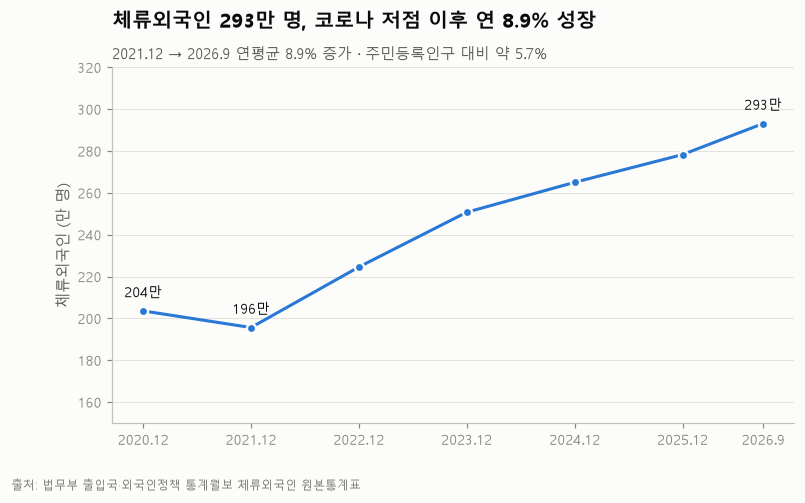

In [3]:
ts = L.load_visa_timeseries()
tot = ts[ts.visa == "총합계"].set_index("date")["count"]
yrs = (tot.index[-1] - tot.index[0]).days / 365.25
cagr_tot = (tot.iloc[-1] / tot.iloc[0]) ** (1 / yrs) - 1
cagr_post = (tot.iloc[-1] / tot.loc["2021-12-31"]) ** (1 / ((tot.index[-1] - pd.Timestamp("2021-12-31")).days / 365.25)) - 1
print(tot.astype(int).to_string())
print(f"\nCAGR 2020.12→2026.9: {cagr_tot:.1%}   |   CAGR 2021.12(코로나 저점)→2026.9: {cagr_post:.1%}")

fig, ax = plt.subplots(figsize=(8, 4.2))
x = tot.index
ax.plot(x, tot / 1e4, color=SERIES[0], marker="o", markersize=6, markeredgecolor=C["surface"], markeredgewidth=1.5)
for d, v in tot.items():
    if d.year in (2021, 2026) or d == tot.index[0]:
        ax.annotate(f"{v/1e4:,.0f}만", (d, v / 1e4), xytext=(0, 9), textcoords="offset points",
                    ha="center", fontsize=9, color=C["ink"])
ax.set_ylim(150, 320); ax.set_ylabel("체류외국인 (만 명)")
ax.set_xticks(x); ax.set_xticklabels([f"{d.year}.{d.month}" for d in x])
ax.set_title(f"체류외국인 {tot.iloc[-1]/1e4:.0f}만 명, 코로나 저점 이후 연 {cagr_post:.1%} 성장")
subtitle(ax, f"2021.12 → 2026.9 연평균 {cagr_post:.1%} 증가 · 주민등록인구 대비 약 5.7%")
ax.grid(axis="x", visible=False)
finish(fig, "fig01_foreign_residents_trend", "법무부 출입국·외국인정책 통계월보 체류외국인 원본통계표")

### 1-2. 외국인 자영업자 규모 — 두 가지 지표
- **조사 기반(A)**: 외국인 비임금근로자(자영업자+무급가족종사자). 표본조사, 15세 이상 상주 외국인.
- **행정 기반(D)**: 외국인 종합소득세 신고 인원. 사업·프리랜서 소득 등 종합소득 신고자로 자영업자의 *상한 프록시*.

category      취업자  비임금근로자  비임금비중
year                            
2012       697.90   26.80   0.04
2013       667.90   20.50   0.03
2014       738.30   28.70   0.04
2015       809.20   29.60   0.04
2016       835.20   33.30   0.04
2017       834.20   35.20   0.04
2018       884.30   38.40   0.04
2019       863.20   37.80   0.04
2020       847.90   44.20   0.05
2021       855.30   44.00   0.05
2022       843.00   50.30   0.06
2023       922.90   50.40   0.05
2024     1,010.00   54.30   0.05
2025     1,109.30   62.30   0.06
비임금근로자 CAGR 2022→2025: 7.4%


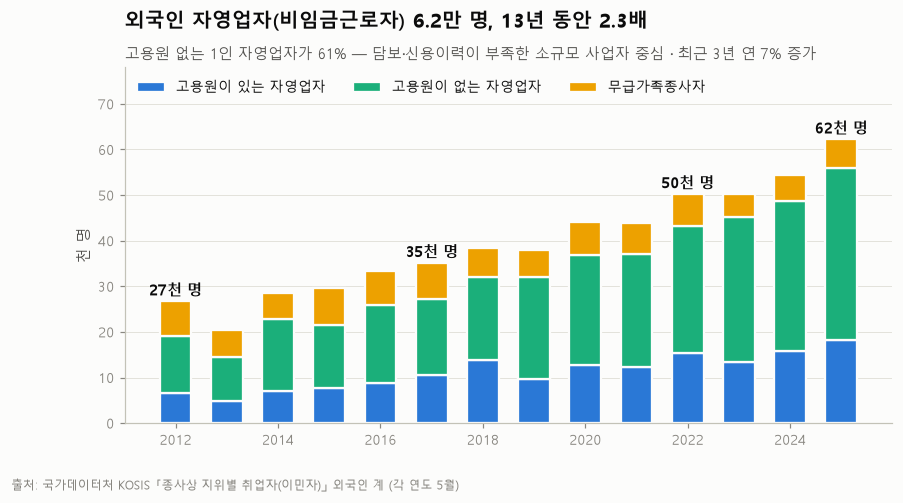

In [4]:
es = sv("employment_status").pivot(index="year", columns="category", values="value")
nw = es[["고용원이 있는 자영업자", "고용원이 없는 자영업자", "무급가족종사자"]]
print(es[["취업자", "비임금근로자"]].assign(비임금비중=lambda d: d.비임금근로자 / d.취업자))
g_nw = (es.loc[2025, "비임금근로자"] / es.loc[2022, "비임금근로자"]) ** (1 / 3) - 1
print(f"비임금근로자 CAGR 2022→2025: {g_nw:.1%}")

fig, ax = plt.subplots(figsize=(9, 4.2))   # KOSIS 통계표로 2012년부터 전 기간을 그린다
bottom = np.zeros(len(nw))
cols = [SERIES[0], SERIES[2], SERIES[3]]
for c, col in zip(nw.columns, cols):
    ax.bar(nw.index, nw[c], bottom=bottom, color=col, width=0.62, label=c, edgecolor=C["surface"], linewidth=1.5)
    bottom += nw[c].values
y_first, y_last = int(nw.index[0]), int(nw.index[-1])
for xi, t in zip(nw.index, es["비임금근로자"]):
    if xi in (y_first, 2017, 2022, y_last):
        ax.text(xi, t + 1.2, f"{t:.0f}천 명", ha="center", fontsize=9.5, color=C["ink"], fontweight="bold")
ax.set_xticks(list(nw.index[::2])); ax.set_ylim(0, 78); ax.set_ylabel("천 명")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3, bbox_to_anchor=(0, 1.0))
solo_share = es.loc[y_last, "고용원이 없는 자영업자"] / es.loc[y_last, "비임금근로자"]
ax.set_title(f"외국인 자영업자(비임금근로자) {es.loc[y_last, '비임금근로자']/10:.1f}만 명, "
             f"{y_last - y_first}년 동안 {es.loc[y_last, '비임금근로자']/es.loc[y_first, '비임금근로자']:.1f}배")
subtitle(ax, f"고용원 없는 1인 자영업자가 {solo_share:.0%} — 담보·신용이력이 부족한 소규모 사업자 중심 · 최근 3년 연 {g_nw:.0%} 증가")
finish(fig, "fig02_foreign_self_employed", "국가데이터처 KOSIS 「종사상 지위별 취업자(이민자)」 외국인 계 (각 연도 5월)")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          9.9885      0.021    471.583      0.000       9.943      10.034
year           0.1662      0.002     69.096      0.000       0.161       0.171
R² = 0.997,  연평균 성장률(추정) = 18.1%
   year       pred         lo         hi
0  2025 311,263.00 279,554.00 346,568.00
1  2026 367,558.00 329,387.00 410,153.00
2  2027 434,034.00 388,026.00 485,498.00
3  2028 512,534.00 457,022.00 574,789.00


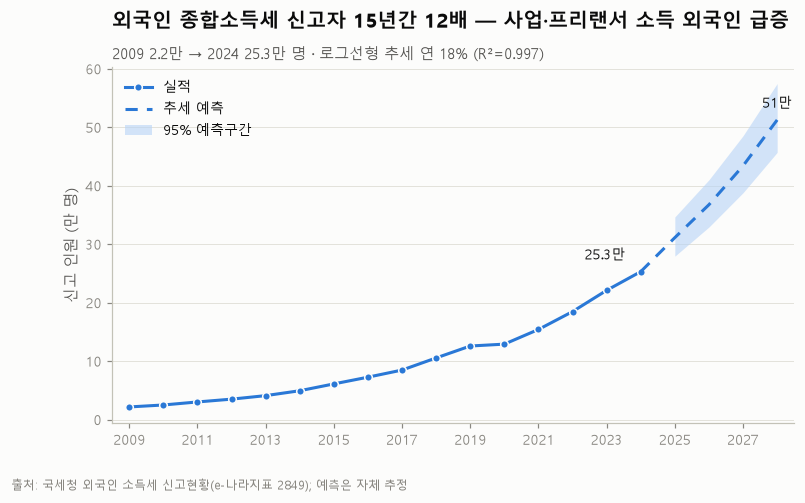

In [5]:
nts = L.load_nts_foreign_income_tax()
nts.to_csv(PROC / "nts_foreign_income_tax.csv", index=False)
# 로그-선형 추세(지수 성장) 회귀 + 2025~2028 예측(95% 예측구간)
X = sm.add_constant(nts.year - 2009)
m = sm.OLS(np.log(nts.filers), X).fit()
fut = pd.DataFrame({"year": range(2025, 2029)})
pr = m.get_prediction(sm.add_constant(fut.year - 2009, has_constant="add")).summary_frame(alpha=0.05)
fut["pred"], fut["lo"], fut["hi"] = np.exp(pr["mean"]), np.exp(pr["obs_ci_lower"]), np.exp(pr["obs_ci_upper"])
print(m.summary().tables[1]); print(f"R² = {m.rsquared:.3f},  연평균 성장률(추정) = {np.exp(m.params.iloc[1]) - 1:.1%}")
print(fut.round(0))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(nts.year, nts.filers / 1e4, color=SERIES[0], marker="o", markersize=5, markeredgecolor=C["surface"], label="실적")
ax.plot([2024] + fut.year.tolist(), [nts.filers.iloc[-1] / 1e4] + (fut.pred / 1e4).tolist(),
        color=SERIES[0], linestyle=(0, (4, 3)), label="추세 예측")
ax.fill_between(fut.year, fut.lo / 1e4, fut.hi / 1e4, color=BLUE[1], alpha=0.6, linewidth=0, label="95% 예측구간")
ax.annotate(f"{nts.filers.iloc[-1]/1e4:.1f}만", (2024, nts.filers.iloc[-1] / 1e4), xytext=(-10, 8),
            textcoords="offset points", ha="right", fontsize=9)
ax.annotate(f"{fut.pred.iloc[-1]/1e4:.0f}만", (2028, fut.pred.iloc[-1] / 1e4), xytext=(0, 8),
            textcoords="offset points", ha="center", fontsize=9)
ax.set_ylabel("신고 인원 (만 명)"); ax.set_xlim(2008.5, 2028.5); ax.grid(axis="x", visible=False)
ax.set_xticks(range(2009, 2029, 2))
ax.legend(loc="upper left")
ax.set_title("외국인 종합소득세 신고자 15년간 12배 — 사업·프리랜서 소득 외국인 급증")
subtitle(ax, f"2009 2.2만 → 2024 25.3만 명 · 로그선형 추세 연 {np.exp(m.params.iloc[1]) - 1:.0%} (R²={m.rsquared:.3f})")
finish(fig, "fig03_nts_foreign_income_tax_filers", "국세청 외국인 소득세 신고현황(e-나라지표 2849); 예측은 자체 추정")

### 1-3. 어떤 업종에서 늘고 있나 — 외국인 취업자 산업 구성 (2024→2025)

year           2012   2013   2014   2015   2016   2017   2018   2019   2020  \
category                                                                      
전기·운수·통신·금융업   9.10   9.30   9.80  11.20  11.10   9.50  14.20  14.00  19.20   
농림어업          37.40  28.00  38.60  37.20  45.20  48.30  49.50  52.10  56.90   
건설업           76.40  57.50  75.10  74.20  72.30  90.30 110.70  95.00  85.50   
사업·개인·공공서비스업 110.70 110.80 114.60 141.20 148.80 147.70 141.80 138.30 142.30   
도소매·숙박·음식점업  128.90 118.20 130.00 147.90 156.70 154.70 163.20 164.50 164.40   
광·제조업        335.40 344.00 370.20 397.70 401.10 383.50 404.90 399.40 379.60   

year           2021   2022   2023   2024   2025    증감   증감률  
category                                                     
전기·운수·통신·금융업  20.70  25.80  25.10  23.10  29.70  6.60  0.29  
농림어업          61.00  45.80  61.00  83.60 100.30 16.70  0.20  
건설업          102.10 102.60 111.80 107.50 107.00 -0.50 -0.00  
사업·개인·공공서비스업 139.60 141.20 143.30 143.90 148.30  4.40  0.

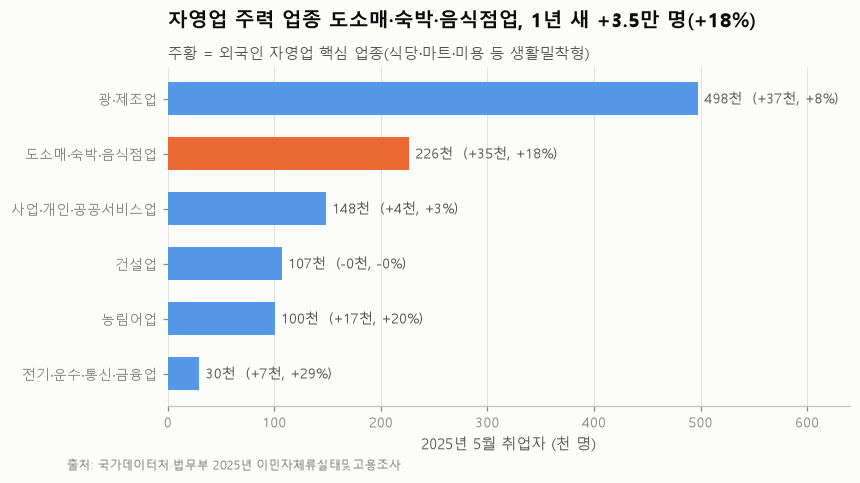

In [6]:
ind = sv("industry").pivot(index="category", columns="year", values="value")
ind["증감"] = ind[2025] - ind[2024]; ind["증감률"] = ind["증감"] / ind[2024]
ind = ind.sort_values(2025)
print(ind)
fig, ax = plt.subplots(figsize=(8, 4))
colors = [SERIES[1] if i == "도소매·숙박·음식점업" else BLUE[5] for i in ind.index]
ax.barh(ind.index, ind[2025], color=colors, height=0.6)
for i, (v, d, r) in enumerate(zip(ind[2025], ind["증감"], ind["증감률"])):
    ax.text(v + 6, i, f"{v:.0f}천  ({'+' if d >= 0 else ''}{d:.0f}천, {r:+.0%})", va="center", fontsize=9, color=C["ink2"])
ax.set_xlim(0, 640); ax.set_xlabel("2025년 5월 취업자 (천 명)"); ax.grid(axis="y", visible=False); bar_ends(ax)
ax.set_title("자영업 주력 업종 도소매·숙박·음식점업, 1년 새 +3.5만 명(+18%)")
subtitle(ax, "주황 = 외국인 자영업 핵심 업종(식당·마트·미용 등 생활밀착형)")
finish(fig, "fig04_industry_mix", "국가데이터처·법무부 2025년 이민자체류실태및고용조사")

---
## 2. 타겟 세분화 — 체류자격이 곧 '금융 적격성'
체류자격에 따라 사업자등록 가능 여부와 체류 안정성(=대출 만기 설정 가능성)이 달라진다.
- **사업 가능·장기**: F-2(거주), F-4(재외동포), F-5(영주), F-6(결혼이민), D-8(기업투자), D-9(무역경영)
- **사업 불가(취업 한정)**: E-9, H-2, E-1~7, D-2/D-4(유학·연수) 등 → 자영업 전환 전 단계 고객(송금·환전 고객)

                       2020.12       2026.9   증가율
사업 가능 체류자격 합계       813,005.00 1,090,886.00  0.34
재외동포(F-4)           466,682.00   614,228.00  0.32
유학·구직(D-2·D-4·D-10) 162,404.00   405,059.00  1.49
비전문·방문취업(E-9·H-2)   391,487.00   374,151.00 -0.04
영주·거주(F-2·F-5)      204,613.00   306,011.00  0.50
결혼이민(F-6)           133,987.00   158,850.00  0.19
전문인력(E-1~E-7)        40,902.00   115,758.00  1.83
기업투자·무역경영(D-8·D-9)    7,723.00    11,797.00  0.53


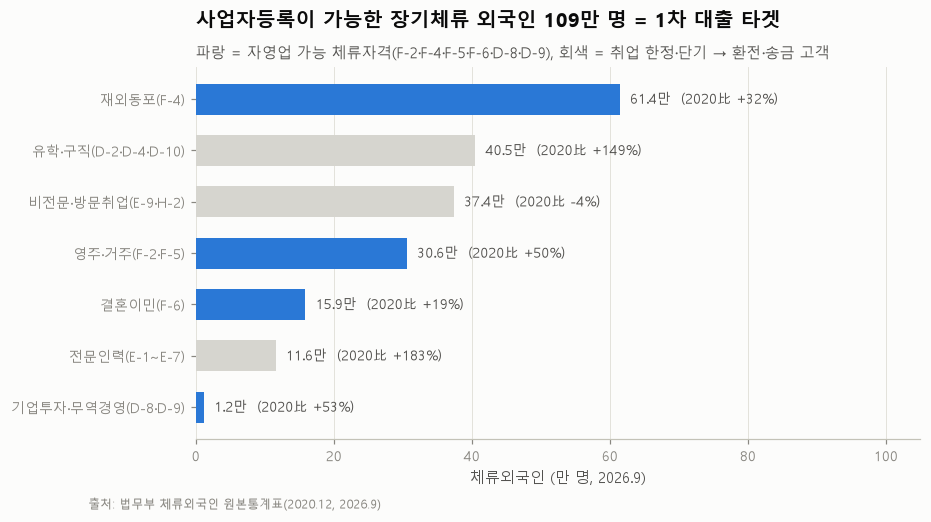

In [7]:
latest = L.RAW / "moj" / "stay_2026_09.xlsx"
nat = L.load_stay_by_nationality(latest)
grp = pd.DataFrame({g: nat[[c for c in codes if c in nat]].sum(axis=1) for g, codes in L.VISA_GROUPS.items()})
grp["기타·단기"] = nat["총합계"] - grp.sum(axis=1)
grp.index = nat["국적"]

# 체류자격 그룹별 추이
ts_w = ts.pivot(index="date", columns="visa", values="count")
grp_ts = pd.DataFrame({g: ts_w[[c for c in codes if c in ts_w]].sum(axis=1) for g, codes in L.VISA_GROUPS.items()})
grp_ts["사업 가능 체류자격 합계"] = ts_w[[c for c in L.BUSINESS_ELIGIBLE if c in ts_w]].sum(axis=1)
grp_ts.to_csv(PROC / "visa_group_timeseries.csv")
chg = pd.DataFrame({"2020.12": grp_ts.iloc[0], "2026.9": grp_ts.iloc[-1]})
chg["증가율"] = chg["2026.9"] / chg["2020.12"] - 1
print(chg.sort_values("2026.9", ascending=False))

biz_now = grp_ts["사업 가능 체류자격 합계"].iloc[-1]
fig, ax = plt.subplots(figsize=(8.5, 4.4))
d = chg.drop("사업 가능 체류자격 합계").sort_values("2026.9")
elig = {"영주·거주(F-2·F-5)", "재외동포(F-4)", "결혼이민(F-6)", "기업투자·무역경영(D-8·D-9)"}
ax.barh(d.index, d["2026.9"] / 1e4, color=[SERIES[0] if i in elig else C["neutral"] for i in d.index], height=0.6)
for i, (v, r) in enumerate(zip(d["2026.9"], d["증가율"])):
    ax.text(v / 1e4 + 1.5, i, f"{v/1e4:.1f}만  (2020比 {r:+.0%})", va="center", fontsize=9, color=C["ink2"])
ax.set_xlim(0, 105); ax.set_xlabel("체류외국인 (만 명, 2026.9)"); ax.grid(axis="y", visible=False); bar_ends(ax)
ax.set_title(f"사업자등록이 가능한 장기체류 외국인 {biz_now/1e4:.0f}만 명 = 1차 대출 타겟")
subtitle(ax, "파랑 = 자영업 가능 체류자격(F-2·F-4·F-5·F-6·D-8·D-9), 회색 = 취업 한정·단기 → 환전·송금 고객")
finish(fig, "fig05_visa_segments", "법무부 체류외국인 원본통계표(2020.12, 2026.9)")

### 2-1. 국적 × 체류자격 — 교차표, 카이제곱 독립성 검정, Cramér's V
표본이 아닌 전수(행정) 자료라 p값은 사실상 항상 0에 수렴한다. 따라서 **효과크기(Cramér's V)**로 연관 강도를 해석한다.

χ²=1,804,120, df=54, p=0.00e+00, Cramér's V=0.44  (df*=min(행,열)-1=6 기준 0.25 이상이면 강한 연관)


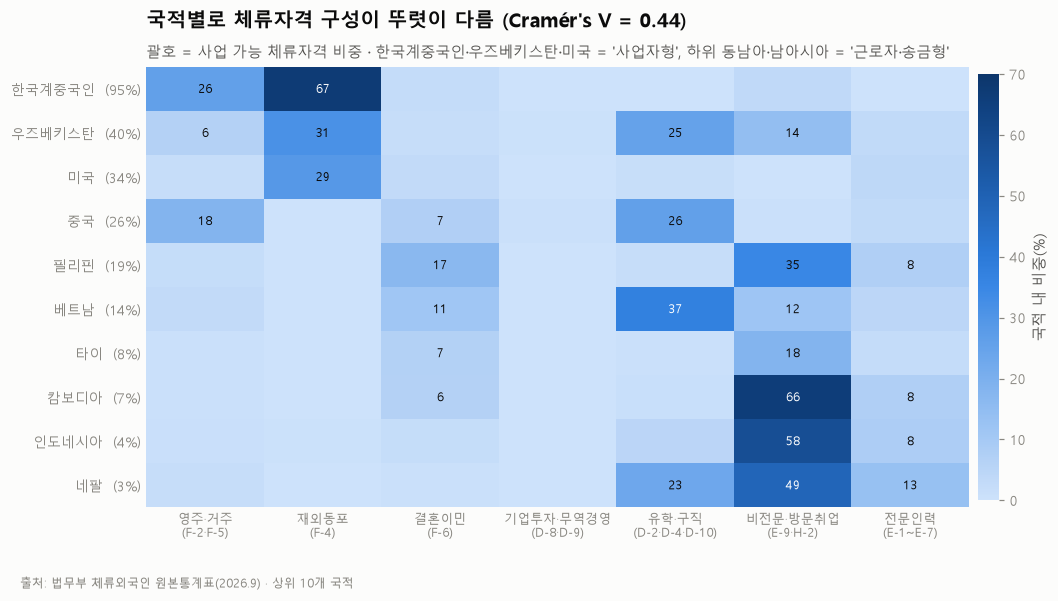

In [8]:
top = grp.loc[grp.sum(axis=1).sort_values(ascending=False).index[:10]]
ct = top.drop(columns="기타·단기")
chi2, p, dof, _ = stats.chi2_contingency(ct.values)
cv = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
print(f"χ²={chi2:,.0f}, df={dof}, p={p:.2e}, Cramér's V={cv:.2f}  (df*=min(행,열)-1={min(ct.shape)-1} 기준 0.25 이상이면 강한 연관)")

share = ct.div(top.sum(axis=1), axis=0) * 100
biz_share = top[list(elig)].sum(axis=1) / top.sum(axis=1) * 100
share = share.loc[biz_share.sort_values(ascending=False).index]
share.to_csv(PROC / "nationality_visa_share.csv")

fig, ax = plt.subplots(figsize=(10, 5.2))
im = ax.imshow(share.values, cmap=SEQ, vmin=0, vmax=70, aspect="auto")
ax.set_xticks(range(share.shape[1])); ax.set_xticklabels([c.replace("(", "\n(") for c in share.columns], fontsize=8.5)
ax.set_yticks(range(share.shape[0])); ax.set_yticklabels([f"{n}  ({biz_share[n]:.0f}%)" for n in share.index])
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j]
        if v >= 5:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8.5, color="#ffffff" if v > 35 else C["ink"])
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.set_label("국적 내 비중(%)")
ax.set_title(f"국적별로 체류자격 구성이 뚜렷이 다름 (Cramér's V = {cv:.2f})")
subtitle(ax, "괄호 = 사업 가능 체류자격 비중 · " + "·".join(share.index[:3]) + " = '사업자형', 하위 동남아·남아시아 = '근로자·송금형'")
fig.text(0.01, -0.03, "출처: 법무부 체류외국인 원본통계표(2026.9) · 상위 10개 국적", fontsize=8, color=C["muted"])
fig.savefig(FIG / "fig06_nationality_visa_heatmap.png"); plt.show()

**해석** — 한국계중국인·중국·미국·우즈베키스탄 등은 F-4/F-5 비중이 높아 *사업자대출* 타겟,
베트남·네팔·캄보디아·인도네시아는 E-9·유학 비중이 높아 *송금·환전 → 향후 체류자격 전환 시 대출*로 이어지는 육성 타겟이다.

---
## 3. 지역 집중도 — 어디에 거점(지점·제휴처)을 둘 것인가
지표: 시군구별 **사업 가능 체류자격 외국인 수**와 **입지계수(LQ)**
$LQ_i = \dfrac{\text{사업가능}_i / \text{외국인}_i}{\text{사업가능}_{전국} / \text{외국인}_{전국}}$ — 1보다 크면 그 지역 외국인이 전국 평균보다 '사업자 전환형'에 특화.

In [9]:
rv = L.load_region_table(L.RAW / "moj" / "regres_region_visa_2026_09.xlsx")
rn = L.load_region_table(L.RAW / "moj" / "regres_region_nat_2026_09.xlsx")
cvisa = L.aggregate_to_city(rv); cnat = L.aggregate_to_city(rn)
cvisa["biz"] = cvisa[[c for c in L.BUSINESS_ELIGIBLE if c in cvisa]].sum(axis=1)
nat_biz = cvisa.biz.sum() / cvisa["총합계"].sum()
cvisa["LQ"] = (cvisa.biz / cvisa["총합계"]) / nat_biz
cvisa["label"] = cvisa["시도"].str.replace("특별자치도|특별자치시|특별시|광역시|통합특별시|도$", "", regex=True).str[:2] + " " + cvisa.city
cvisa.to_csv(PROC / "region_business_eligible.csv", index=False)
print(f"전국 등록+거소 외국인 {cvisa['총합계'].sum():,.0f}명 중 사업 가능 체류자격 {cvisa.biz.sum():,.0f}명 ({nat_biz:.1%})")
top15 = cvisa.sort_values("biz", ascending=False).head(15)
print(f"상위 15개 시군구가 사업가능 외국인의 {top15.biz.sum() / cvisa.biz.sum():.1%} 차지")
top15[["label", "총합계", "biz", "LQ"]]

전국 등록+거소 외국인 2,281,331명 중 사업 가능 체류자격 1,082,277명 (47.4%)
상위 15개 시군구가 사업가능 외국인의 47.8% 차지


,label,총합계,biz,LQ
32,경기 안산시,101718,"76,454.00",1.58
31,경기 시흥시,73839,"54,282.00",1.55
30,경기 수원시,67822,"48,769.00",1.52
28,경기 부천시,56908,"45,203.00",1.67
125,서울 구로구,50264,"43,746.00",1.83
138,서울 영등포구,49086,"42,207.00",1.81
48,경기 화성시,71500,"28,152.00",0.83
154,인천 부평구,32019,"27,197.00",1.79
45,경기 평택시,52756,"25,173.00",1.01
126,서울 금천구,28899,"25,153.00",1.83


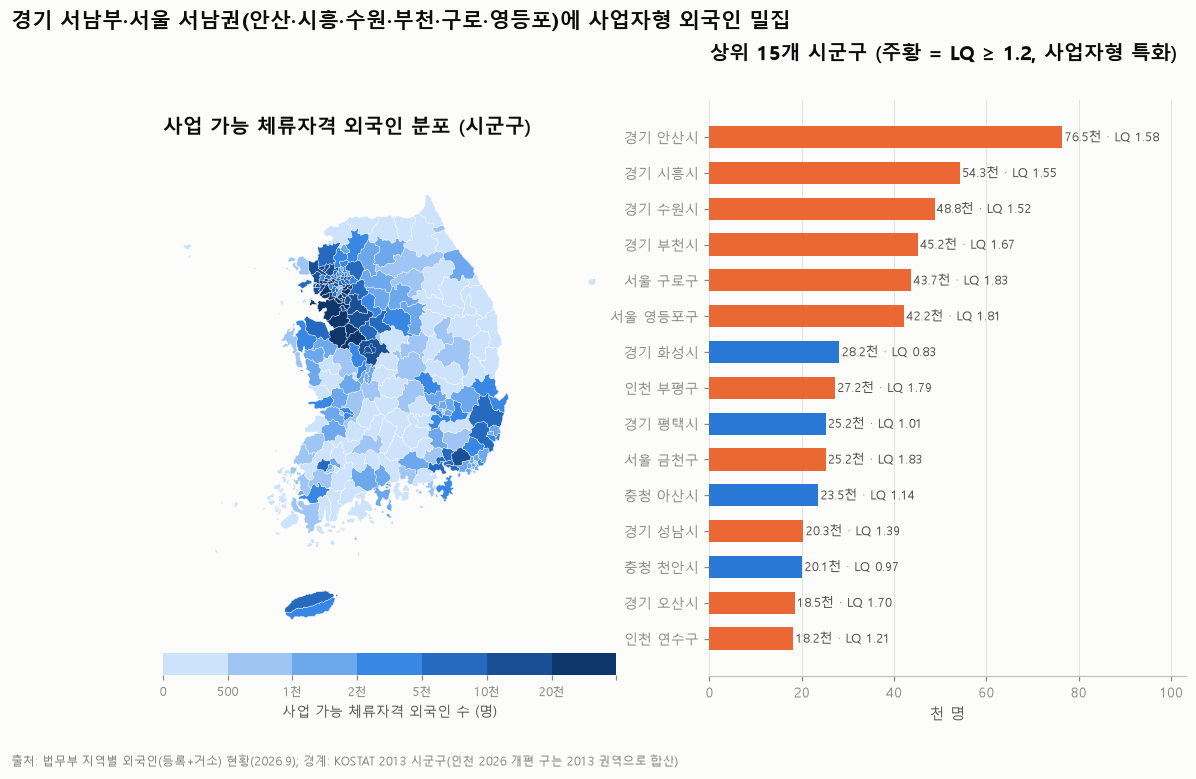

In [10]:
feats = L.load_geo_features()
fmap, unmatched = L.match_geo(cvisa, feats)
assert not unmatched, unmatched

def draw_map(ax, values, cmap, norm, edge="#ffffff"):
    patches, cols = [], []
    for k, f in enumerate(feats):
        g = f["geometry"]
        polys = g["coordinates"] if g["type"] == "MultiPolygon" else [g["coordinates"]]
        v = values.get(fmap.get(k), np.nan)
        for poly in polys:
            patches.append(MplPolygon(np.array(poly[0]), closed=True))
            cols.append(C["neutral"] if pd.isna(v) else cmap(norm(v)))
    pc = PatchCollection(patches, facecolor=cols, edgecolor=edge, linewidth=0.25)
    ax.add_collection(pc); ax.autoscale_view(); ax.set_aspect(1.2)
    ax.set_axis_off()

bins = [0, 500, 1000, 2500, 5000, 10000, 20000, max(40000, int(cvisa.biz.max()) + 1)]
cmap_b = ListedColormap([BLUE[i] for i in (0, 2, 4, 6, 8, 10, 12)])
norm_b = BoundaryNorm(bins, cmap_b.N)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(12, 6.8), gridspec_kw={"width_ratios": [1, 1.05]})
draw_map(ax, cvisa.biz.to_dict(), cmap_b, norm_b)
sm_ = mpl.cm.ScalarMappable(norm=norm_b, cmap=cmap_b)
cb = fig.colorbar(sm_, ax=ax, orientation="horizontal", fraction=0.04, pad=0.02, ticks=bins)
cb.ax.set_xticklabels([f"{b//1000}천" if b >= 1000 else str(b) for b in bins[:-1]] + [""], fontsize=8); cb.outline.set_visible(False)
cb.set_label("사업 가능 체류자격 외국인 수 (명)", fontsize=9)
ax.set_title("사업 가능 체류자격 외국인 분포 (시군구)")

t = top15.iloc[::-1]
ax2.barh(t.label, t.biz / 1e3, color=[SERIES[1] if lq >= 1.2 else BLUE[7] for lq in t.LQ], height=0.62)
for i, (v, lq) in enumerate(zip(t.biz, t.LQ)):
    ax2.text(v / 1e3 + 0.5, i, f"{v/1e3:.1f}천 · LQ {lq:.2f}", va="center", fontsize=8.5, color=C["ink2"])
ax2.set_xlim(0, t.biz.max() / 1e3 * 1.35); ax2.grid(axis="y", visible=False); ax2.spines["left"].set_visible(False)
ax2.set_xlabel("천 명"); ax2.set_title("상위 15개 시군구 (주황 = LQ ≥ 1.2, 사업자형 특화)")
fig.suptitle("경기 서남부·서울 서남권(" + "·".join(top15.city.str.replace("시$|구$", "", regex=True).head(6)) + ")에 사업자형 외국인 밀집", x=0.01, ha="left",
             fontsize=14, fontweight="bold", y=1.0)
fig.text(0.01, -0.01, "출처: 법무부 지역별 외국인(등록+거소) 현황(2026.9); 경계: KOSTAT 2013 시군구(인천 2026 개편 구는 2013 권역으로 합산)",
         fontsize=8, color=C["muted"])
fig.savefig(FIG / "fig07_region_map_top15.png"); plt.show()

---
## 4. 지역 군집분석 (K-means) — 지역 유형별 상품 전략
변수(시군구 단위, 표준화): 외국인 규모(log), 사업가능 자격 비중, 비전문·방문취업 비중, 유학 비중, 한국계중국인 비중, 베트남 비중, 기타아시아 비중.
외국인 1,000명 이상 시군구만 사용(소규모 지역의 비율 노이즈 제거). k는 실루엣 계수로 선택.

In [11]:
df = cvisa.merge(cnat[["시도", "city"] + [c for c in ["한국계중국", "한국계중국인", "베트남", "중국"] if c in cnat]], on=["시도", "city"])
kc = "한국계중국" if "한국계중국" in df else "한국계중국인"
tot_ = df["총합계"]
feat = pd.DataFrame({
    "외국인 규모(log)": np.log10(tot_),
    "사업가능 자격 비중": df.biz / tot_,
    "E-9·H-2 비중": (df.get("E9", 0) + df.get("H2", 0)) / tot_,
    "유학(D-2·D-4) 비중": (df.get("D2", 0) + df.get("D4", 0)) / tot_,
    "한국계중국인 비중": df[kc] / tot_,
    "베트남 비중": df["베트남"] / tot_,
    "중국(한족 등) 비중": df["중국"] / tot_,
}, index=df.index)
mask = tot_ >= 1000
Z = StandardScaler().fit_transform(feat[mask])
scores = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z)) for k in range(3, 7)}
print("silhouette:", {k: round(v, 3) for k, v in scores.items()})
K = 4 if abs(scores.get(4, 0) - max(scores.values())) < 0.03 else max(scores, key=scores.get)
km = KMeans(K, n_init=50, random_state=0).fit(Z)
df.loc[mask, "cluster"] = km.labels_
prof = feat[mask].groupby(km.labels_).mean()
prof["시군구 수"] = pd.Series(km.labels_).value_counts().sort_index().values
prof["외국인 합계"] = tot_[mask].groupby(km.labels_).sum().values
print(f"선택된 k = {K}"); prof

silhouette: {3: 0.333, 4: 0.28, 5: 0.238, 6: 0.291}


선택된 k = 3


,외국인 규모(log),사업가능 자격 비중,E-9·H-2 비중,유학(D-2·D-4) 비중,한국계중국인 비중,베트남 비중,중국(한족 등) 비중,시군구 수,외국인 합계
0,3.84,0.32,0.07,0.38,0.10,0.25,0.15,52,493883
1,3.56,0.22,0.31,0.05,0.07,0.27,0.04,103,546093
2,4.16,0.63,0.11,0.09,0.36,0.09,0.09,53,1218900


{np.int32(0): '대학가 유학생형', np.int32(1): '산업단지 근로자형', np.int32(2): '동포·정주 사업자형'}
[대학가 유학생형] 대표 지역: 충청 청주시, 서울 광진구, 서울 동대문구, 경상 경산시, 경상 경주시
[산업단지 근로자형] 대표 지역: 경상 김해시, 경상 창원시, 경기 파주시, 충청 음성군, 경상 거제시
[동포·정주 사업자형] 대표 지역: 경기 안산시, 경기 시흥시, 경기 화성시, 경기 수원시, 경기 부천시


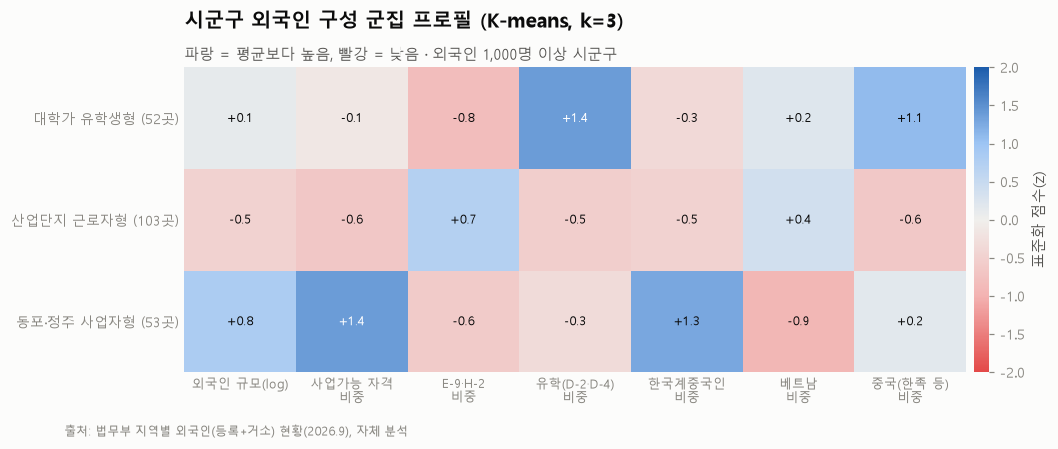

In [12]:
# 군집 명명: 대표 특성 비중이 가장 높은 군집에 순서대로 이름을 붙인다 (중복 없이)
zprof = pd.DataFrame(StandardScaler().fit(feat[mask]).transform(prof[feat.columns]), columns=feat.columns, index=prof.index)
names, left = {}, list(prof.index)
for col, nm in [("사업가능 자격 비중", "동포·정주 사업자형"), ("E-9·H-2 비중", "산업단지 근로자형"),
                ("유학(D-2·D-4) 비중", "대학가 유학생형")]:
    if not left: break
    i = prof.loc[left, col].idxmax(); names[i] = nm; left.remove(i)
for i in left: names[i] = f"혼합형 {i}"
names = dict(sorted(names.items()))
df["cluster_name"] = df.cluster.map(names)
df.to_csv(PROC / "region_clusters.csv", index=False)
print(names)
for i in sorted(names):
    ex = df[df.cluster == i].sort_values("총합계", ascending=False).label.head(5).tolist()
    print(f"[{names[i]}] 대표 지역: {', '.join(ex)}")

fig, ax = plt.subplots(figsize=(9.5, 0.6 * K + 1.8))
zz = zprof.rename(index=names)
im = ax.imshow(zz.values, cmap=DIV, norm=TwoSlopeNorm(0, -2, 2), aspect="auto")
ax.set_xticks(range(zz.shape[1])); ax.set_xticklabels([c.replace(" 비중", "\n비중") for c in zz.columns], fontsize=8.5)
ax.set_yticks(range(K)); ax.set_yticklabels([f"{n} ({int(prof.loc[i,'시군구 수'])}곳)" for i, n in names.items()])
for i in range(zz.shape[0]):
    for j in range(zz.shape[1]):
        ax.text(j, i, f"{zz.values[i, j]:+.1f}", ha="center", va="center", fontsize=8.5,
                color="#ffffff" if abs(zz.values[i, j]) > 1.3 else C["ink"])
ax.grid(False); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.set_label("표준화 점수(z)")
ax.set_title(f"시군구 외국인 구성 군집 프로필 (K-means, k={K})")
subtitle(ax, "파랑 = 평균보다 높음, 빨강 = 낮음 · 외국인 1,000명 이상 시군구")
fig.text(0.01, -0.05, "출처: 법무부 지역별 외국인(등록+거소) 현황(2026.9), 자체 분석", fontsize=8, color=C["muted"])
fig.savefig(FIG / "fig08_cluster_profile.png"); plt.show()

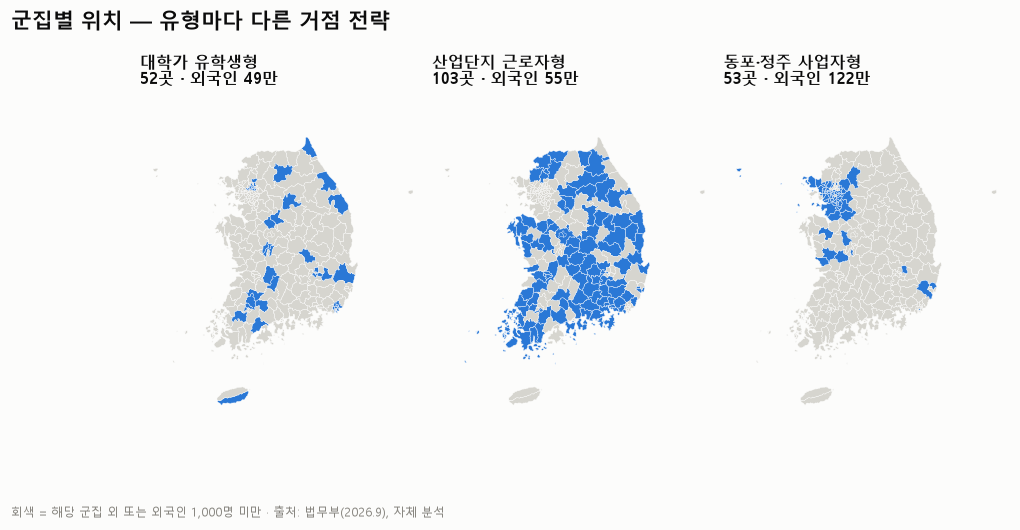

In [13]:
# 지도: 군집별 소형 다중 지도 (색 하나 = 해당 군집 강조, 나머지 회색)
fig, axes = plt.subplots(1, K, figsize=(3.4 * K, 4.6))
for ax, i in zip(axes, sorted(names)):
    vals = {r: 1.0 for r in df.index[df.cluster == i]}
    draw_map(ax, vals, ListedColormap([SERIES[0]]), BoundaryNorm([0, 2], 1))
    ax.set_title(f"{names[i]}\n{int(prof.loc[i,'시군구 수'])}곳 · 외국인 {prof.loc[i,'외국인 합계']/1e4:.0f}만", fontsize=10.5)
fig.suptitle("군집별 위치 — 유형마다 다른 거점 전략", x=0.01, ha="left", fontsize=14, fontweight="bold", y=0.98)
fig.subplots_adjust(top=0.82, wspace=0.02)
fig.text(0.01, -0.02, "회색 = 해당 군집 외 또는 외국인 1,000명 미만 · 출처: 법무부(2026.9), 자체 분석", fontsize=8, color=C["muted"])
fig.savefig(FIG / "fig09_cluster_maps.png"); plt.show()

---
## 5. 환전·송금 수요

                   usd    residents
2020 10,728,800,000.00 2,036,075.00
2021 11,816,200,000.00 1,956,781.00
2022  9,858,700,000.00 2,245,912.00
2023 12,076,500,000.00 2,507,584.00
2024 14,332,800,000.00 2,650,783.00
2025 14,309,400,000.00 2,783,247.00
Pearson r = 0.78 (p=0.070, n=6) — 표본이 작아 방향성 참고용
체류외국인 1만 명 증가당 송금 42백만 달러 증가 (단순회귀)


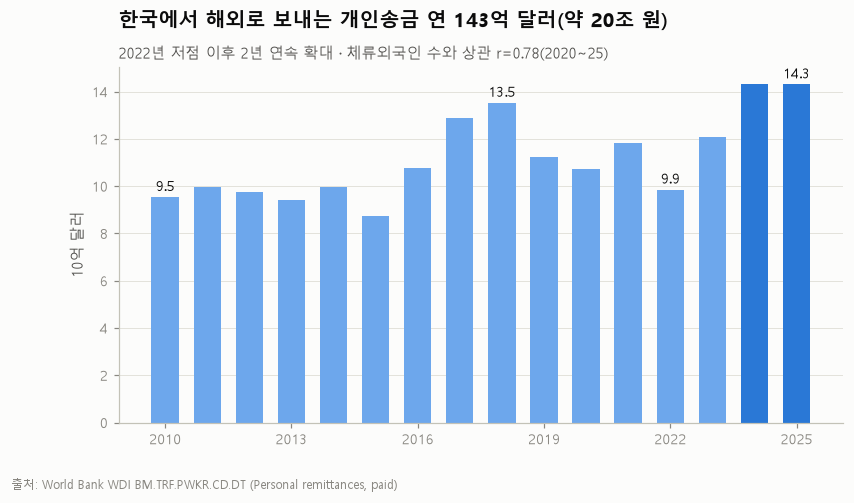

In [14]:
rem = L.load_wb_remittances_paid()
rem = rem[rem.year >= 2010]
fx_y = L.load_ecos_monthly_fx().assign(year=lambda d: d.date.dt.year).groupby("year")["KRW/USD"].mean()
rem["krw_jo"] = rem.usd * rem.year.map(fx_y) / 1e12  # ECOS 연평균 환율(2016~)로 원화 환산
rem.to_csv(PROC / "remittances_paid_korea.csv", index=False)

# 체류외국인 연말 인원과의 상관 (2020~2025, n=6 → 참고용)
yr_tot = tot[tot.index.month == 12]; yr_tot.index = yr_tot.index.year
j = rem.set_index("year").join(yr_tot.rename("residents"), how="inner")
r, pr_ = stats.pearsonr(j.residents, j.usd)
print(j[["usd", "residents"]]); print(f"Pearson r = {r:.2f} (p={pr_:.3f}, n={len(j)}) — 표본이 작아 방향성 참고용")
sl = stats.linregress(j.residents, j.usd)
print(f"체류외국인 1만 명 증가당 송금 {sl.slope*1e4/1e6:,.0f}백만 달러 증가 (단순회귀)")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.bar(rem.year, rem.usd / 1e9, color=[SERIES[0] if y >= 2024 else BLUE[4] for y in rem.year], width=0.65)
for y, v in zip(rem.year, rem.usd):
    if y in (2010, 2018, 2022, 2025):
        ax.text(y, v / 1e9 + 0.25, f"{v/1e9:.1f}", ha="center", fontsize=9)
ax.set_ylabel("10억 달러"); ax.grid(axis="x", visible=False); ax.set_xticks(rem.year[::3])
ax.set_title("한국에서 해외로 보내는 개인송금 연 143억 달러(약 20조 원)")
subtitle(ax, f"2022년 저점 이후 2년 연속 확대 · 체류외국인 수와 상관 r={r:.2f}(2020~25)")
finish(fig, "fig10_remittances_paid", "World Bank WDI BM.TRF.PWKR.CD.DT (Personal remittances, paid)")

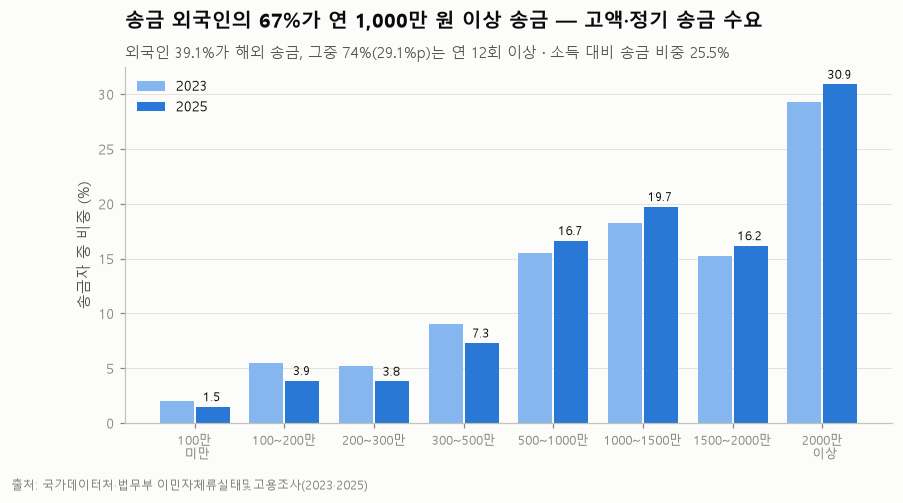

In [15]:
ra = sv("remit_amount").pivot(index="category", columns="year", values="value")
order = ["100만 원 미만", "100~200만 원", "200~300만 원", "300~500만 원", "500~1000만 원",
         "1000~1500만 원", "1500~2000만 원", "2000만 원 이상"]
ra = ra.loc[order]
fig, ax = plt.subplots(figsize=(9, 4.2))
xx = np.arange(len(order)); w = 0.38
ax.bar(xx - w / 2 - 0.01, ra[2023], w, color=BLUE[3], label="2023")
ax.bar(xx + w / 2 + 0.01, ra[2025], w, color=SERIES[0], label="2025")
for xi, v in zip(xx, ra[2025]):
    ax.text(xi + w / 2, v + 0.5, f"{v:.1f}", ha="center", fontsize=8.5)
ax.set_xticks(xx); ax.set_xticklabels([o.replace(" 원", "").replace("만", "만\n") for o in order], fontsize=8.5)
ax.set_ylabel("송금자 중 비중 (%)"); ax.grid(axis="x", visible=False); ax.legend(loc="upper left")
heavy = ra.loc[["1000~1500만 원", "1500~2000만 원", "2000만 원 이상"], 2025].sum()
ax.set_title(f"송금 외국인의 {heavy:.0f}%가 연 1,000만 원 이상 송금 — 고액·정기 송금 수요")
subtitle(ax, "외국인 39.1%가 해외 송금, 그중 74%(29.1%p)는 연 12회 이상 · 소득 대비 송금 비중 25.5%")
finish(fig, "fig11_remittance_amount_dist", "국가데이터처·법무부 이민자체류실태및고용조사(2023·2025)")

         월간 변동률 표준편차(%)  연율화 변동성(%)  최대 월간 변동(%)    기간 최고    기간 최저
KRW/USD            1.90        6.59         6.28 1,527.30 1,066.70
KRW/CNY            1.59        5.51         5.70   225.51   162.66


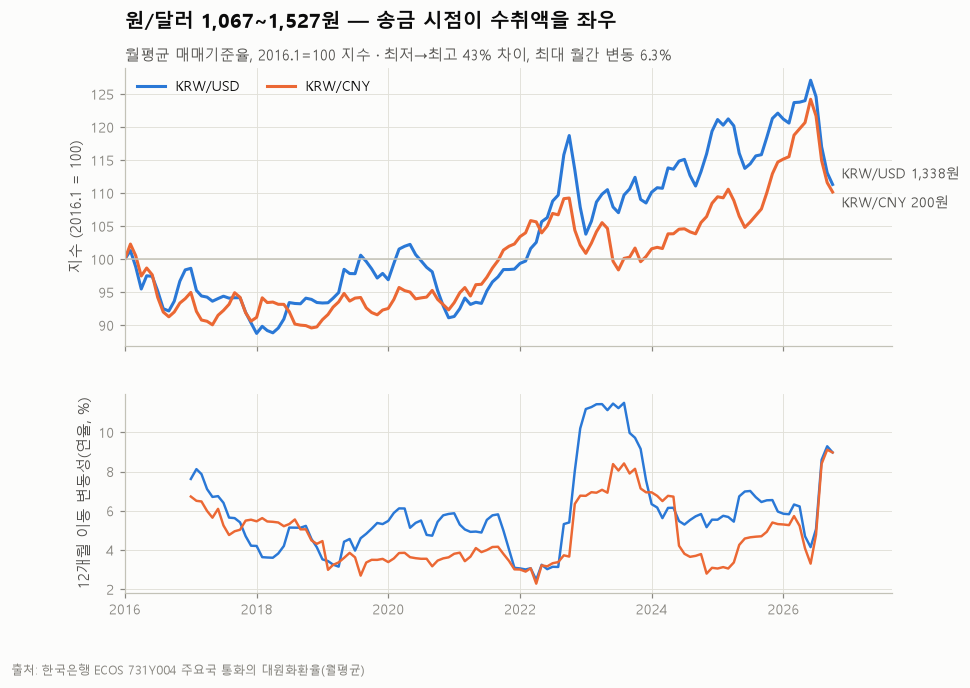

In [16]:
fx = L.load_ecos_monthly_fx().set_index("date")
fx.to_csv(PROC / "ecos_monthly_fx.csv")
ret = np.log(fx).diff().dropna()
vol = ret.rolling(12).std() * np.sqrt(12) * 100
summary = pd.DataFrame({"월간 변동률 표준편차(%)": ret.std() * 100,
                        "연율화 변동성(%)": ret.std() * np.sqrt(12) * 100,
                        "최대 월간 변동(%)": ret.abs().max() * 100,
                        "기간 최고": fx.max(), "기간 최저": fx.min()})
print(summary.round(2))
idx = fx / fx.iloc[0] * 100

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [1.4, 1]})
for c, col, dy in zip(fx.columns, [SERIES[0], SERIES[1]], [7, -7]):
    a1.plot(idx.index, idx[c], color=col, label=c)
    a1.annotate(f"{c} {fx[c].iloc[-1]:,.0f}원", (idx.index[-1], idx[c].iloc[-1]), xytext=(6, dy),
                textcoords="offset points", va="center", fontsize=9, color=C["ink2"])
a1.axhline(100, color=C["axis"], linewidth=1)
a1.set_ylabel("지수 (2016.1 = 100)"); a1.legend(loc="upper left", ncol=2)
rng = fx["KRW/USD"].max() / fx["KRW/USD"].min() - 1
a1.set_title(f"원/달러 {fx['KRW/USD'].min():,.0f}~{fx['KRW/USD'].max():,.0f}원 — 송금 시점이 수취액을 좌우")
subtitle(a1, f"월평균 매매기준율, 2016.1=100 지수 · 최저→최고 {rng:.0%} 차이, 최대 월간 변동 {ret['KRW/USD'].abs().max():.1%}")
for c, col in zip(vol.columns, [SERIES[0], SERIES[1]]):
    a2.plot(vol.index, vol[c], color=col, linewidth=1.6)
a2.set_ylabel("12개월 이동 변동성(연율, %)")
a2.set_xlim(fx.index[0], fx.index[-1] + pd.Timedelta(days=330))
fig.text(0.01, -0.01, "출처: 한국은행 ECOS 731Y004 주요국 통화의 대원화환율(월평균)", fontsize=8, color=C["muted"])
fig.savefig(FIG / "fig12_fx_volatility.png"); plt.show()

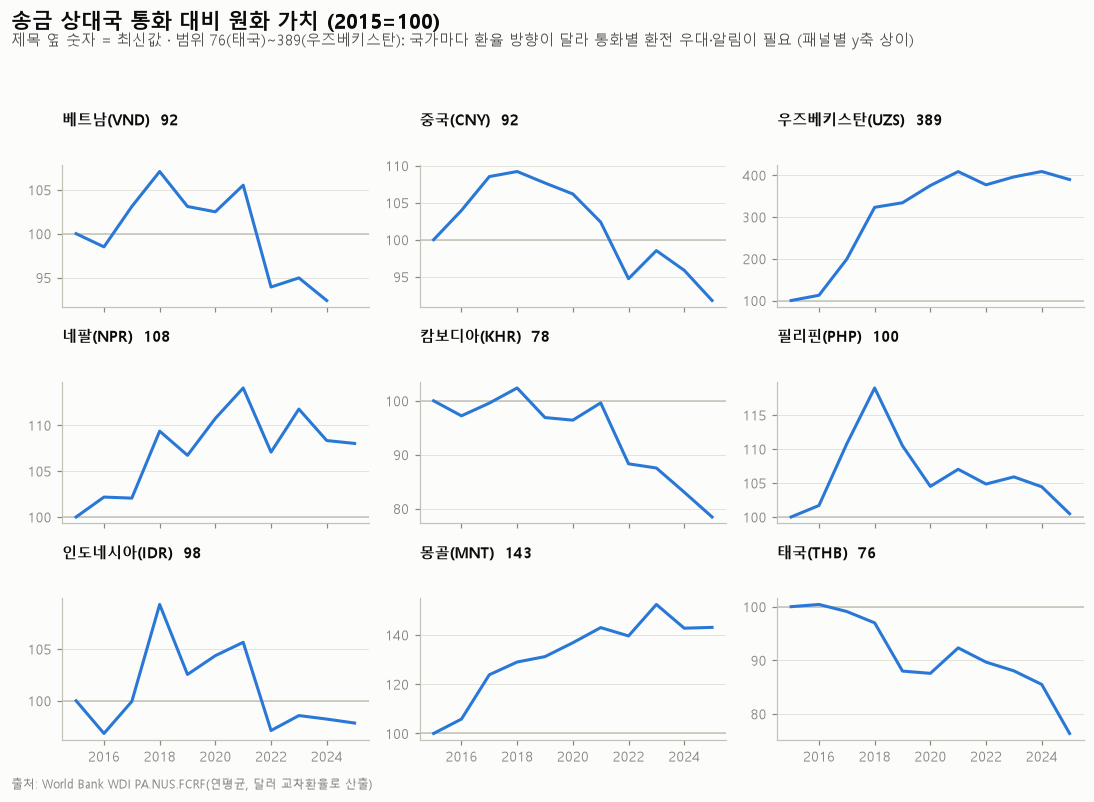

In [17]:
# 송금 상대국 통화 가치: 1원으로 살 수 있는 현지통화 (2015=100). 100보다 크면 원화 대비 현지통화 약세 → 같은 원화로 더 많이 송금
cross = L.load_wb_fx_cross().loc[2015:]
cidx = cross / cross.loc[2015] * 100
show = ["베트남(VND)", "중국(CNY)", "우즈베키스탄(UZS)", "네팔(NPR)", "캄보디아(KHR)", "필리핀(PHP)", "인도네시아(IDR)", "몽골(MNT)", "태국(THB)"]
show = [s for s in show if s in cidx]
fig, axes = plt.subplots(3, 3, figsize=(10, 7), sharex=True)  # 국가별 y축 개별(우즈베키스탄 규모 차이)
for ax, c in zip(axes.flat, show):
    s = cidx[c].dropna()
    ax.axhline(100, color=C["axis"], linewidth=1)
    ax.plot(s.index, s, color=SERIES[0])
    ax.set_title(f"{c}  {s.iloc[-1]:.0f}", fontsize=10, loc="left")
    ax.grid(axis="x", visible=False)
for ax in axes.flat[len(show):]: ax.set_visible(False)
fig.suptitle("송금 상대국 통화 대비 원화 가치 (2015=100)", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.0)
last = cidx[show].ffill().iloc[-1].sort_values()
fig.text(0.01, 0.955, f"제목 옆 숫자 = 최신값 · 범위 {last.min():.0f}({last.idxmin().split('(')[0]})~{last.max():.0f}({last.idxmax().split('(')[0]}): "
         "국가마다 환율 방향이 달라 통화별 환전 우대·알림이 필요 (패널별 y축 상이)", fontsize=9.5, color=C["ink2"])
fig.text(0.01, -0.01, "출처: World Bank WDI PA.NUS.FCRF(연평균, 달러 교차환율로 산출)", fontsize=8, color=C["muted"])
fig.tight_layout(rect=(0, 0, 1, 0.94))
fig.savefig(FIG / "fig13_source_country_fx.png"); plt.show()

---
## 6. 잠재 시장규모 추정 (TAM · SAM · SOM)
모든 가정은 아래 `ASSUME` 딕셔너리에 모아 두었다 — 공모전 발표 시 근거와 함께 제시하고, 바꾸면 결과가 즉시 재계산된다.

In [18]:
ASSUME = {
    "송금액 구간 대표값(만원)": [50, 150, 250, 400, 750, 1250, 1750, 2500],  # 최상위 구간(2000만+)은 2,500만으로 가정
    "환전·송금 수수료율": 0.010,          # 송금액 대비 평균 수수료+환전마진 (가정)
    "평균 사업자대출(만원)": 3000,        # 1인 소상공인 운영자금 수준 (가정)
    "대출 순이자마진": 0.030,            # NIM (가정)
    "3년 목표 점유율_송금": 0.05,
    "3년 목표 점유율_대출": 0.05,
}
pop15 = sv("population", 2025).value.iloc[0] * 1e3
senders_rate = sv("remit_freq", 2025).set_index("category").loc["송금함", "value"] / 100
ra25 = ra[2025] / 100
mean_remit = float((ra25.values * np.array(ASSUME["송금액 구간 대표값(만원)"])).sum())  # 만원/년
senders = pop15 * senders_rate
tam_remit = senders * mean_remit * 1e4               # 원
wb_krw = rem.set_index("year").loc[2025, "usd"] * fx_y.loc[2025]
print(f"송금 외국인 {senders/1e4:.1f}만 명 × 1인 평균 {mean_remit:,.0f}만 원 = 연 {tam_remit/1e12:.1f}조 원")
print(f"교차검증: World Bank 2025 개인송금 지급 {wb_krw/1e12:.1f}조 원 (내국인 송금 포함 → 상한)")

self_emp = es.loc[2025, "비임금근로자"] * 1e3 - es.loc[2025, "무급가족종사자"] * 1e3
filers = nts.filers.iloc[-1]
biz_ratio = cvisa.biz.sum() / cvisa["총합계"].sum()

funnel = pd.DataFrame([
    ("송금·환전", "TAM", "15세 이상 상주 외국인", pop15, None),
    ("송금·환전", "SAM", "해외 송금 외국인(39.1%)", senders, senders * mean_remit * 1e4 * ASSUME["환전·송금 수수료율"]),
    ("송금·환전", "SOM", f"3년 점유율 {ASSUME['3년 목표 점유율_송금']:.0%}", senders * ASSUME["3년 목표 점유율_송금"],
     senders * ASSUME["3년 목표 점유율_송금"] * mean_remit * 1e4 * ASSUME["환전·송금 수수료율"]),
    ("사업자대출", "TAM", "외국인 종합소득세 신고자(2024)", filers, None),
    ("사업자대출", "SAM", "외국인 자영업자(무급가족 제외, 2025)", self_emp,
     self_emp * ASSUME["평균 사업자대출(만원)"] * 1e4 * ASSUME["대출 순이자마진"]),
    ("사업자대출", "SOM", f"3년 점유율 {ASSUME['3년 목표 점유율_대출']:.0%}", self_emp * ASSUME["3년 목표 점유율_대출"],
     self_emp * ASSUME["3년 목표 점유율_대출"] * ASSUME["평균 사업자대출(만원)"] * 1e4 * ASSUME["대출 순이자마진"]),
], columns=["상품", "단계", "정의", "인원", "연 수익(원)"])
funnel.to_csv(PROC / "market_sizing.csv", index=False)
print(funnel.assign(인원=lambda d: d.인원.map("{:,.0f}".format),
                    **{"연 수익(억원)": lambda d: (d["연 수익(원)"] / 1e8).round(1)}).drop(columns="연 수익(원)").to_string(index=False))

송금 외국인 66.2만 명 × 1인 평균 1,473만 원 = 연 9.8조 원
교차검증: World Bank 2025 개인송금 지급 20.4조 원 (내국인 송금 포함 → 상한)
   상품  단계                      정의        인원  연 수익(억원)
송금·환전 TAM           15세 이상 상주 외국인 1,692,300       NaN
송금·환전 SAM        해외 송금 외국인(39.1%)   662,400    975.60
송금·환전 SOM               3년 점유율 5%    33,120     48.80
사업자대출 TAM     외국인 종합소득세 신고자(2024)   253,050       NaN
사업자대출 SAM 외국인 자영업자(무급가족 제외, 2025)    56,000    504.00
사업자대출 SOM               3년 점유율 5%     2,800     25.20


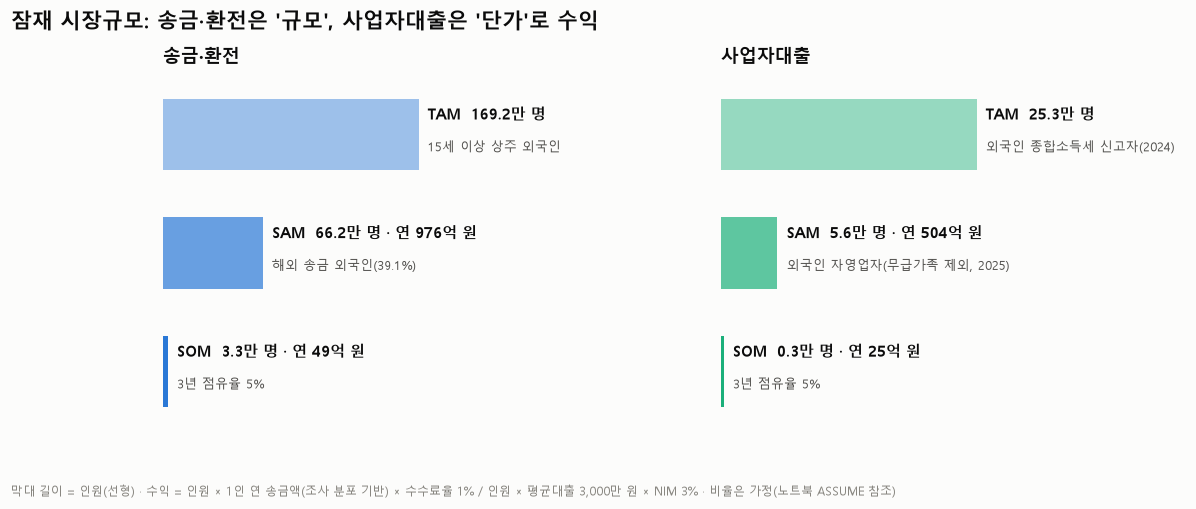

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (prod, d), col in zip(axes, funnel.groupby("상품", sort=False), [SERIES[0], SERIES[2]]):
    d = d.reset_index(drop=True)
    widths = d.인원 / d.인원.max() * 0.55
    for i, r in d.iterrows():
        w = max(widths[i], 0.006)
        ax.barh(-i, w, left=0, color=col, alpha=[0.45, 0.7, 1.0][i], height=0.6)
        rev = "" if pd.isna(r["연 수익(원)"]) else f" · 연 {r['연 수익(원)']/1e8:,.0f}억 원"
        ax.text(w + 0.02, -i + 0.1, f"{r.단계}  {r.인원/1e4:,.1f}만 명{rev}", ha="left", va="bottom",
                fontsize=10, color=C["ink"], fontweight="bold")
        ax.text(w + 0.02, -i - 0.05, r.정의, ha="left", va="top", fontsize=8.5, color=C["ink2"])
    ax.set_xlim(0, 1); ax.set_ylim(-2.5, 0.5); ax.set_axis_off()
    ax.set_title(prod, fontsize=12, pad=8)
fig.suptitle("잠재 시장규모: 송금·환전은 '규모', 사업자대출은 '단가'로 수익", x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.02)
fig.text(0.01, -0.03, "막대 길이 = 인원(선형) · 수익 = 인원 × 1인 연 송금액(조사 분포 기반) × 수수료율 1% / 인원 × 평균대출 3,000만 원 × NIM 3% · 비율은 가정(노트북 ASSUME 참조)",
         fontsize=8, color=C["muted"])
fig.savefig(FIG / "fig14_market_sizing_funnel.png"); plt.show()

---
## 7. 핵심 인사이트 → 상품 제안

| # | 데이터 근거 | 인사이트 | 상품·전략 |
|---|---|---|---|
| 1 | 체류외국인 293만(2021.12 이후 연 8.9%↑), 종소세 신고 외국인 25만(15년 12배) | 시장이 구조적으로 성장 | 조기 진입 시 선점 효과 |
| 2 | 외국인 자영업자 6.2만(3년 +24%), 61%가 1인 자영업 | 담보·신용이력 없는 소규모 사업자 | **체류자격 연계 소액 사업자대출**: 체류기간 내 만기, 매출(카드·POS) 기반 심사 |
| 3 | 사업 가능 체류자격 F-2·F-4·F-5·F-6·D-8·D-9 | 체류자격이 상환능력·체류안정성의 대리지표 | 자격별 한도·금리 차등(F-5 > F-2/F-6 > F-4 > D-8/9) |
| 4 | 국적×자격 Cramér's V = 0.44(강한 연관) | 동포·중국계 = 사업자형, 동남아 = 근로자·송금형 | 국적별 언어·채널 차별화, 근로자형은 송금 고객 → 자격 전환 시 대출로 육성 |
| 5 | 상위 15개 시군구에 사업가능 외국인 집중, LQ 특화 지역 존재 | 거점 효율이 높음 | 안산·영등포·구로 등 1차 거점 + 다국어 상담 제휴점 |
| 6 | 송금자 39%, 그중 1,000만 원+ 67%, 월 1회+ 74% | 고액·정기 송금 수요 | **환율우대 정기송금 + 목표환율 예약환전**, 송금실적을 대출 신용평가에 반영(대안신용) |
| 7 | 원/달러·원/위안 변동성, 송금국 통화별 차이 | 환율 리스크가 실질 소득을 좌우 | 통화별 우대·알림 서비스, 사업자 결제대금 환헤지 |

**한계** — (1) 외국인 자영업자의 국적·체류자격 교차는 공개 집계표에 없어 체류자격 인구로 대리 추정,
(2) 종합소득세 신고자는 프리랜서·근로 외 소득자를 포함한 상한, (3) 송금 최상위 구간 대표값과 수수료율·대출단가는 가정,
(4) 송금-체류외국인 상관은 n=6으로 참고용. MDIS 마이크로데이터(이민자체류실태및고용조사) 신청 시 자영업자 단위 분석으로 고도화 가능.